In [3]:
import pandas as pd
import matplotlib as mtp

#pd.set_option('display.max_rows', None)      # toutes les lignes
#pd.set_option('display.max_columns', None)   # toutes les colonnes
#pd.set_option('display.width', None)         # pas de retour à la ligne forcé
#pd.set_option('display.max_colwidth', None)  # contenu des cellules en entier
pd.reset_option('display')

distance = pd.read_csv("../data/distances.csv")
schedule = pd.read_csv("../data/released_schedule.csv")



## Rapport Data Quality
Cette partie est dédié a des opérations diverses afin d'observé la qualité de nos donnée ainsi que pour mettre en place nos différentes théories et spécifications futures

#### Analyse des données null ou NaN

On vérifie la présence de NaN dans la distance pour les fournisseurs


In [37]:
distance[distance.isnull().any(axis=1)]


,supplier_id,distance
1,SUP_00002,NaN
11,SUP_00012,NaN
29,SUP_00030,NaN
30,SUP_00031,NaN
46,SUP_00047,NaN
49,SUP_00050,NaN
83,SUP_00084,NaN
114,SUP_00115,NaN
129,SUP_00130,NaN
136,SUP_00137,NaN


On vérifie la présence de NaN ou 0 dans la table schedule

In [38]:
schedule[schedule.isna().any(axis=1)]


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
1303,2026-11-23,SUP_00046,MAT_000685,PLT_001,ULP_0051,0.0,NaN,NaN,2026-01-30,2026-11-08
1755,2026-11-10,SUP_00112,MAT_000611,PLT_004,ULP_0017,18.0,NaN,NaN,2026-11-06,2026-11-08
2120,2026-11-09,SUP_00109,MAT_000522,PLT_002,ULP_0025,271.0,NaN,NaN,2026-11-04,2026-11-08
2178,2026-12-08,SUP_00133,MAT_001031,PLT_002,ULP_0022,32.0,NaN,NaN,2026-11-04,2026-11-08
2354,2026-11-09,SUP_00117,MAT_000613,PLT_002,ULP_0022,30.0,NaN,NaN,2026-11-04,2026-11-08
...,...,...,...,...,...,...,...,...,...,...
5410,2026-12-14,SUP_00001,MAT_000333,PLT_004,ULP_0010,352.0,NaN,0.42,2026-11-06,2026-11-08
5411,2026-12-15,SUP_00001,MAT_000333,PLT_004,ULP_0010,208.0,NaN,0.42,2026-11-06,2026-11-08
5412,2026-12-17,SUP_00001,MAT_000333,PLT_004,ULP_0010,104.0,NaN,0.42,2026-11-06,2026-11-08
5413,2026-12-18,SUP_00001,MAT_000333,PLT_004,ULP_0010,176.0,NaN,0.42,2026-11-06,2026-11-08


In [40]:
# Nombre de lignes contenant des quantités à 0
n = (schedule["schedule_quantity"] == 0).sum()
print(f"{n} lignes à 0 ({n / len(schedule):.1%})")

959 lignes à 0 (16.7%)


L'analyse révèle la présence de nombreuse valeur NaN et 0, les valeurs 0 sont présentes uniquement pour la colonne schedule_quantity. Les NaN quant à eux sont présents dans les colonnes weight et volumes. Les colonnes ayant 0 dans schedule quantity on forcément leurs valeurs à NaN dans weight et quantity, le cas inverse n'est pas vrai.

Liste des fournisseurs sans distance mais quand même présent dans le dataset "released_scheduled"

In [39]:
# Fournisseur ayant des distances manquantes présent dans le planning de livraison
supplier_ids = distance[distance.isnull().any(axis=1)]['supplier_id'].unique()
schedule[schedule['supplier_id'].isin(supplier_ids)]

,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
1548,2027-01-01,SUP_00047,MAT_001199,PLT_004,ULP_0027,20.0,140.7,1.20,2026-11-06,2026-11-08
3178,2026-11-17,SUP_00130,MAT_000903,PLT_002,ULP_0008,0.0,0.0,0.42,2026-09-16,2026-11-08
3308,2026-11-20,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
3309,2026-11-26,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
3310,2026-11-27,SUP_00130,MAT_000563,PLT_002,ULP_0008,10.0,142.9,1.20,2026-11-04,2026-11-08
5376,2026-11-17,SUP_00130,MAT_000010,PLT_001,ULP_0028,1.0,63.0,0.42,2026-11-04,2026-11-08


#### Analyse des valeurs abbérantes des datasets


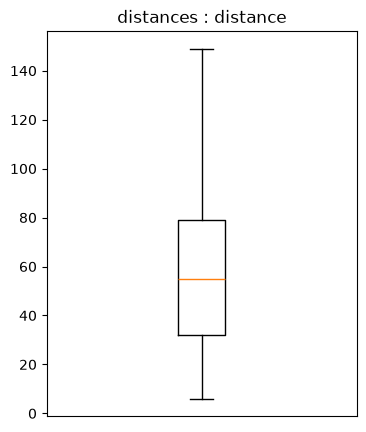

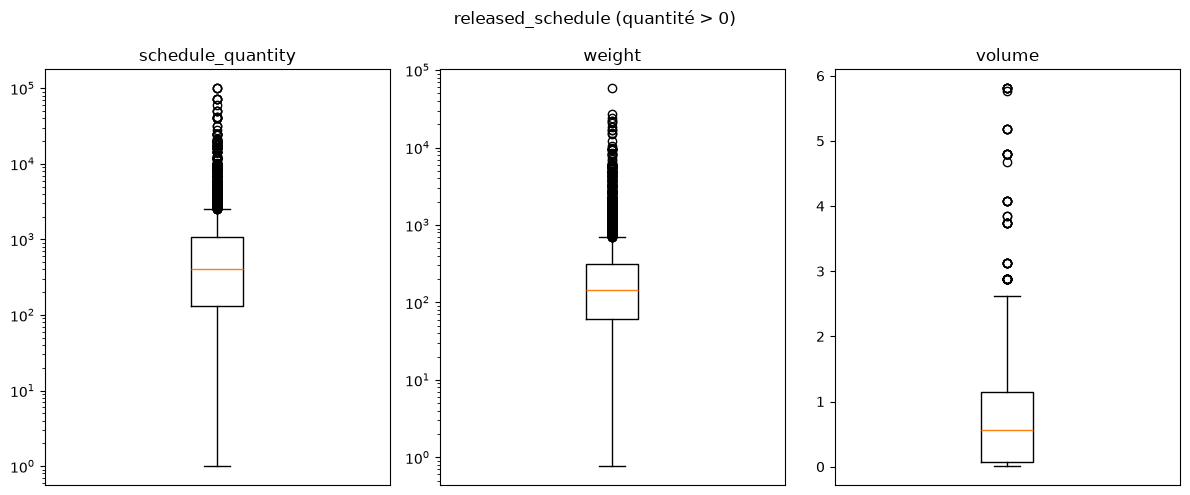

In [5]:
import matplotlib.pyplot as plt

# --- distances ---
fig, ax = plt.subplots(figsize=(4, 5))
ax.boxplot(distance["distance"].dropna())
ax.set_title("distances : distance")
ax.set_xticks([])
plt.show()

# --- schedule : une colonne par sous-graphique (les échelles sont très différentes) ---
cols = ["schedule_quantity", "weight", "volume"]
livraisons = schedule[schedule["schedule_quantity"] > 0]  # on enlève les jours sans livraison

fig, axes = plt.subplots(1, len(cols), figsize=(12, 5))
for ax, col in zip(axes, cols):
    ax.boxplot(livraisons[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
    if col != "volume":
        ax.set_yscale("log")

fig.suptitle("released_schedule (quantité > 0)")
plt.tight_layout()
plt.show()


On observe les valeurs de poids abberantes par jour

In [7]:
# Lignes seules > 24,5 T
schedule_higher_to_24 = schedule[schedule.weight > 24500].sort_values("weight", ascending=False)
schedule_higher_to_24

# couple jour dont le poids total dépasse 24,5 T 
couple_day = (schedule.groupby(["supplier_id", "plant", "date"])[["weight", "volume"]]
                      .sum()
                      .reset_index())

big_couple_days = couple_day[couple_day.weight > 24500].sort_values("weight", ascending=False)
big_couple_days

,supplier_id,plant,date,weight,volume
515,SUP_00046,PLT_004,2026-11-11,46733.64,6.45408
518,SUP_00046,PLT_004,2026-12-02,32306.82,9.31872
778,SUP_00074,PLT_003,2026-12-15,29351.45,2.52000
517,SUP_00046,PLT_004,2026-11-25,26535.24,7.37568
364,SUP_00037,PLT_002,2026-11-27,25722.70,39.00800


Observation des lignes dupliquées sur les champs date, plant, material et supplier_id. Afin d'analyser si des livraisons en double pourraient etre évitées.

In [ ]:

grouped = schedule.groupby(['date', 'plant', 'material', 'supplier_id']).agg(
    nb_rows=('supplier_id', 'size'),
    unloading_points=('unloading_point', lambda s: sorted(s.dropna().unique())),
    row_ids=('supplier_id', lambda s: list(s.index)),  # numéro de la ligne dans le fichier original
).reset_index()
grouped[grouped['nb_rows'] > 1]


Seul le unloading point diffère, les autres colonnes sont identiques. On peut donc les agregger si le poid/volume ne depasse aps les capcitées du camion

## Liste des Spécifications, Hypothèses et contraintes


A partir de nos observations précédentes, nous avons regroupé plusieurs hypothèse durant nos réfléxions :

- On regroupe plusieurs lignes par semaine en une seule, où chacun a un volume attribué (un contenant) qui n’est peut être pas utilisé à sa pleine capacité. N’ayant pas plus d’information sur le volume total et occupé du contenant on suppose qu'on ne peut regrouper les volumes, nos estimations seront donc majorées.

- Un même matériau peut être vendu par plusieurs fournisseurs, notre tâche s’arrête à l’optimisation des lignes, mais pour aller plus loin nous pourrions également optimiser le choix du fournisseur pour un matériau et une usine donnée.


In [ ]:
# les materiaux vendus par plusieurs fournisseurs
materials = schedule.groupby('material')['supplier_id'].agg(
    nb_suppliers='nunique',
    suppliers=lambda s: sorted(s.dropna().unique())
)
multi_suppliers = materials[materials['nb_suppliers'] > 1]
multi_suppliers

- Le poids renseigné est le poids total correspondant au poids fixe du volume et de la quantité de pièce * le poids unitaire de la pièce


A la suite de la mise en place de nos différentes hypothèses  Nous avons relevé des specifications propre au projet :

- SF-01 : L’outil importe le planning (CSV), les distances (CSV) et la grille tarifaire (PDF). 

- SF-02 : L’outil ne prend en compte que les lignes avec une quantité supérieure à 0.

- SF-03 : L’outil consolide les besoins par couple fournisseur × usine, jamais deux usines dans un même camion 

- SF-04 : L’outil attribue à chaque couple un profil de livraison : une fréquence (1, 2, 3 ou 5 fois par semaine) et des jours fixes. 

- SF-05 : L’outil retient la fréquence la plus basse possible qui respecte les contraintes. 

- SF-06 : Un besoin peut être livré en avance, de 7 jours au maximum, mais jamais en retard. 

- SF-07 : Un camion ne dépasse jamais 24,5 t ni 110,4 m³. Au-delà, l’outil ajoute un camion. 

- SF-08 : L’outil répartit les jours de livraison entre les couples d’une même usine (lissage). 

- SF-09 : L’outil produit la sortie 1, le profil de chaque couple.

- SF-10 : L’outil produit la sortie 2, le contenu de chaque camion (materials, quai, quantité, poids, volume).

- SF-11 : L’outil produit la sortie 3, l’économie par couple, en € et en %.

- SF-12 : Chaque ligne de besoin est livrée une fois et une seule, sans oubli ni doublon. 

- SF-13 : Les résultats sont consultables et exportables. 


## Dictionnaire des données

#### Table `distances.csv`
Distance entre chaque fournisseur et le point de consolidation. 156 lignes, une par fournisseur.

| Champ | Description | Type | Contraintes | Exemple |
|---|---|---|---|---|
| supplier_id | Identifiant du fournisseur | Texte | Clé primaire, unique, non nul | SUP_00001 |
| distance | Distance fournisseur → point de consolidation | Décimal | ≥ 0, peut être nul | 47 |

#### Table `released_schedule.csv`
Programme de livraison (release schedule) envoyé aux fournisseurs. 5 728 lignes, une par date × fournisseur × article × usine × quai.

| Champ | Description | Type | Contraintes | Exemple |
|---|---|---|---|---|
| date | Date de livraison demandée | Date | Non nul | 2026-11-11 |
| supplier_id | Fournisseur qui expédie | Texte | Clé étrangère → distances.supplier_id | SUP_00091 |
| material | Référence de la pièce | Texte | Non nul | MAT_000110 |
| plant | Usine de destination | Texte | Non nul | PLT_004 |
| unloading_point | Quai de déchargement dans l'usine | Texte | Non nul | ULP_0027 |
| schedule_quantity | Quantité à livrer | Décimal | ≥ 0 ; 0 = pas de besoin | 5 000 |
| weight | Poids de la ligne | Décimal | ≥ 0, peut être nul | 92,6 |
| volume | Volume de la ligne | Décimal | > 0, peut être nul | 0,4116 |
| transmission_date | Date d'envoi du programme au fournisseur | Date | Non nul, ≤ version_date | 2026-11-06 |
| version_date | Version du programme | Date | Valeur unique | 2026-11-08 |

#### Clés et relations
| Élément | Définition |
|---|---|
| Clé primaire schedule | (date, supplier_id, material, plant, unloading_point), sans doublon |
| Clé de consolidation | fournisseur × usine × date |



## Pipeline de traitement 

### Schedule

In [4]:
nb_avant = len(schedule)

#on ne garde que les lignes avec une quantité strictement supérieure à 0
df_filtre = schedule[schedule['schedule_quantity'] > 0].copy()

nb_apres = len(df_filtre)
nb_supprimees = nb_avant - nb_apres

print(f"Nombre de lignes avant filtrage : {nb_avant}")
print(f"Nombre de lignes apres filtrage : {nb_apres}")
print(f"Nombre de lignes supprimees (quantite = 0) : {nb_supprimees}")



Nombre de lignes avant filtrage : 5728
Nombre de lignes apres filtrage : 4769
Nombre de lignes supprimees (quantite = 0) : 959


Nous avons choisi de ne garder que les lignes dont la quantité est strictement supérieure à O, car une quantité nulle signifie l'absence de besoin de livraison ce jour-là. Ce choix est cohérent avec les données : sur ces 959 lignes, le poids est systématiquement égal à O. Après filtrage, nous retrouvons bien le même nombre de lignes que dans l'énoncé (4 769 lignes sur 5 728).

In [6]:
schedule["date"] = pd.to_datetime(schedule["date"])
schedule = schedule[~((schedule["date"].dt.month == 1) & (schedule["date"].dt.day == 1))]
print(schedule["date"].max())

2026-12-30 00:00:00
